<a href="https://colab.research.google.com/github/wonhoyeo-oss/CV2026/blob/main/SLOC03_CNN_MNIST_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN (Convolutional Neural Network)
##### checked 24.08.15 leebyunggook

In [15]:
import numpy as np
import tensorflow as tf
from IPython.display import Image
tf.random.set_seed(1)

In [16]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras import backend as K
from tensorflow.keras.losses import categorical_crossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from matplotlib import pyplot as plt

# Preprocessing

In [17]:
# collect MNIST data
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [18]:
# sample to show gray scale values
print(x_train[0][12])

[  0   0   0   0   0   0   0   0   0   0   0  11 190 253  70   0   0   0
   0   0   0   0   0   0   0   0   0   0]


In [19]:
# sample to show labels for first train data to 10th train data
print(y_train[0:9])

[5 0 4 1 9 2 1 3 1]


In [20]:
print("test data has " + str(x_test.shape[0]) + " samples")
print("every test data is " + str(x_test.shape[1])
      + " * " + str(x_test.shape[2]) + " image")

test data has 10000 samples
every test data is 28 * 28 image


In [21]:
# reshape data
x_train = np.reshape(x_train, (60000,28,28,1))
x_test = np.reshape(x_test, (10000,28,28,1))

print(x_train.shape)
print(x_test.shape)

(60000, 28, 28, 1)
(10000, 28, 28, 1)


In [22]:
# normalization
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

gray_scale = 255
x_train /= gray_scale
x_test /= gray_scale

In [23]:
# change label to one hot encoding
num_classes = 10
y_train_categorical = tf.keras.utils.to_categorical(y_train, num_classes)
y_test_categorical = tf.keras.utils.to_categorical(y_test, num_classes)

### We will implement below CNN

In [24]:
Image(url= "https://raw.githubusercontent.com/captainchargers/deeplearning/master/img/practice_cnn.png", width=800, height=400)

In [25]:
model = Sequential()
model.add(Conv2D(16, kernel_size=(5, 5), activation='relu', input_shape=(28,28,1),padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Conv2D(32, kernel_size=(5, 5), activation='relu',padding='same'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())
model.add(Dense(128, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))

In [26]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1568)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       200,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 215,370 (841.29 KB)

 Trainable params: 215,370 (841.29 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
model.compile(loss=categorical_crossentropy, optimizer=Adam(), metrics=['accuracy'])

In [28]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [29]:
#callbacks = [EarlyStopping(monitor='val_accuracy', patience=2, restore_best_weights=False),
#  ModelCheckpoint(filepath='./best_model.h5', monitor='val_accuracy', save_best_only=True)]

In [30]:
model.fit(x_train, y_train_categorical, batch_size=500, epochs=10, verbose=1, validation_split = 0.1) #, callbacks=callbacks)

Epoch 1/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 42s 378ms/step - accuracy: 0.8737 - loss: 0.4622 - val_accuracy: 0.9647 - val_loss: 0.1208
Epoch 2/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 42s 384ms/step - accuracy: 0.9679 - loss: 0.1071 - val_accuracy: 0.9800 - val_loss: 0.0722
Epoch 3/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 81s 374ms/step - accuracy: 0.9785 - loss: 0.0720 - val_accuracy: 0.9850 - val_loss: 0.0599
Epoch 4/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 42s 386ms/step - accuracy: 0.9836 - loss: 0.0563 - val_accuracy: 0.9868 - val_loss: 0.0518
Epoch 5/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 41s 381ms/step - accuracy: 0.9862 - loss: 0.0467 - val_accuracy: 0.9872 - val_loss: 0.0465
Epoch 6/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 40s 369ms/step - accuracy: 0.9881 - loss: 0.0394 - val_accuracy: 0.9888 - val_loss: 0.0453
Epoch 7/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 40s 360ms/step - accuracy: 0.9897 - loss: 0.0342 - val_accuracy: 0.9880 - val_loss: 0.0451
Epoch 8/10
108/108 ━━━━━━━━━━━━━━━━━━━━ 39s 364ms/step - accuracy: 0.9910 - loss: 0

In [31]:
score = model.evaluate(x_test, y_test_categorical, verbose=0)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.03142620623111725
Test accuracy: 0.9894000291824341


In [32]:
i=200
image = x_test[i]*255
print(image.shape)
#print((image))

(28, 28, 1)


(28, 28)


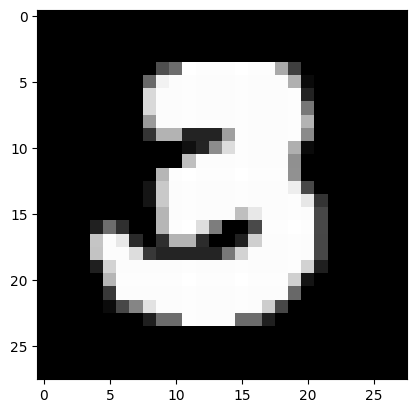

In [33]:
image = np.squeeze(image)
print(image.shape)
plt.imshow(image, cmap='gray')

In [34]:
print(y_test[i])
y_test_categorical[i]

3


array([0., 0., 0., 1., 0., 0., 0., 0., 0., 0.])

In [35]:
pred = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


In [36]:
np.set_printoptions(edgeitems=10, linewidth=130, formatter=dict(float=lambda x: "%4.2f" % x))
print(pred)

[[0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00]
 [0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 [0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 ...
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 [1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00

In [37]:
print(y_test_categorical)

[[0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00]
 [0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 [0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 ...
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 1.00]
 [1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 1.00 0.00 0.00 0.00 0.00 0.00]
 [0.00 0.00 0.00 0.00 0.00 1.00 0.00 0.00

In [38]:
s = 300
m = 20
images = x_test[s:s+m]*255
labels = y_test[s:s+m]

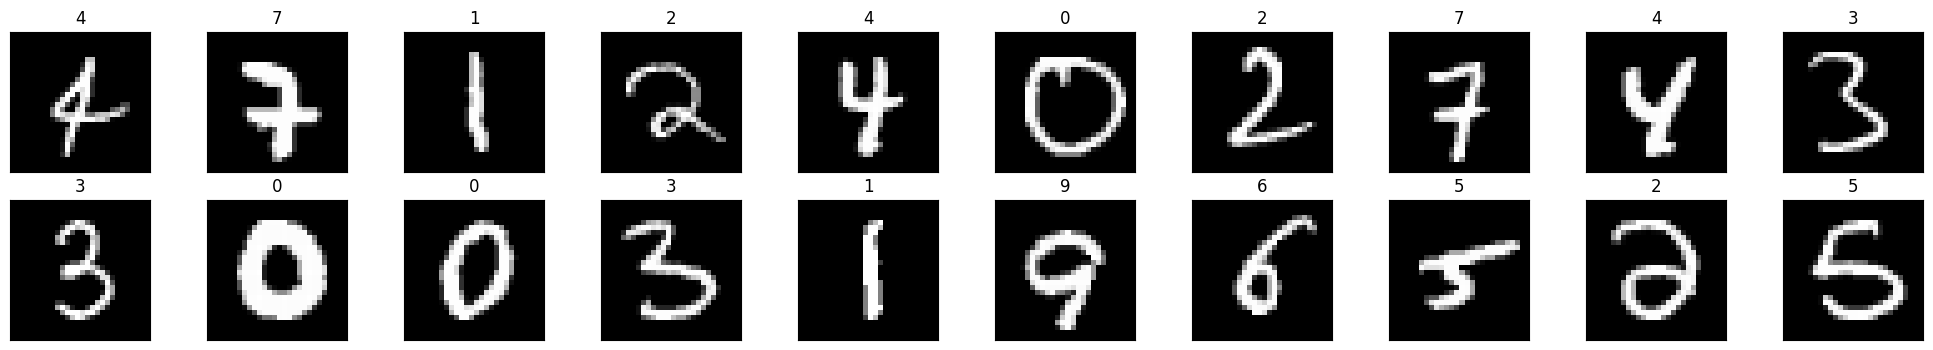

In [39]:
fig = plt.figure(figsize=(25, 4))
for idx in np.arange(m):
  ax = fig.add_subplot(2, (int)(m/2), idx+1, xticks=[], yticks=[])
  ax.imshow(np.squeeze(images[idx]), cmap='gray')
  ax.set_title(str(labels[idx].item()))